In [1]:
import numpy as np
from zfish._io import import16chFlt
from zfish.utils import *
from zfish.openfield import *
from zfish.local_path import *

code_id = "0513 - Square OF 2D"
loc = os.path.join(figpath, code_id)
os.makedirs(loc, exist_ok=True)

3it [00:14,  4.94s/it]


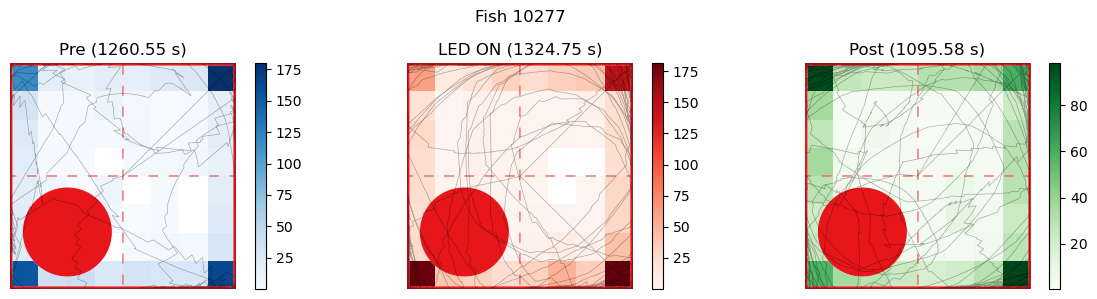

3it [00:37, 12.56s/it]


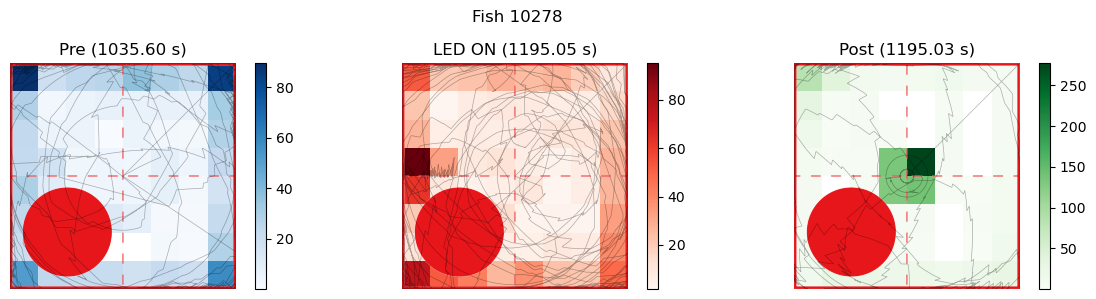

3it [00:16,  5.34s/it]


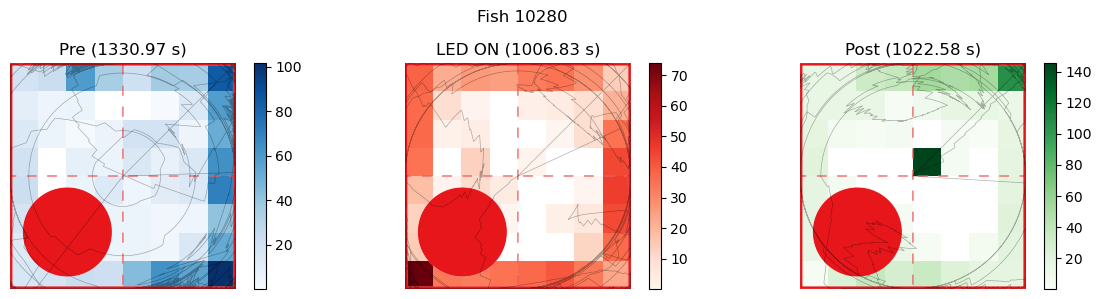

3it [00:15,  5.17s/it]


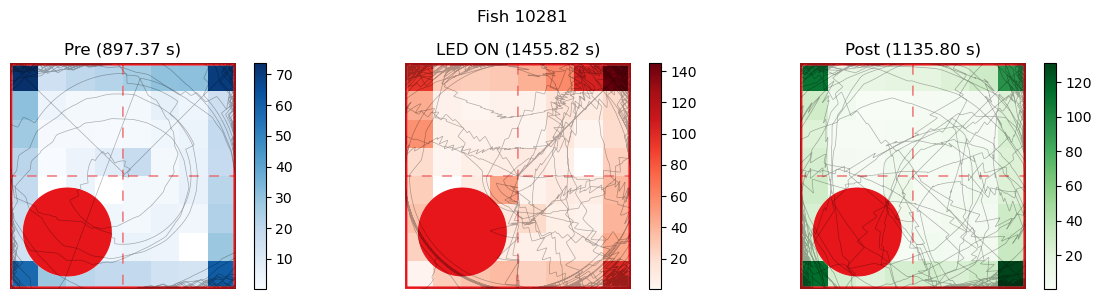

3it [00:11,  3.86s/it]


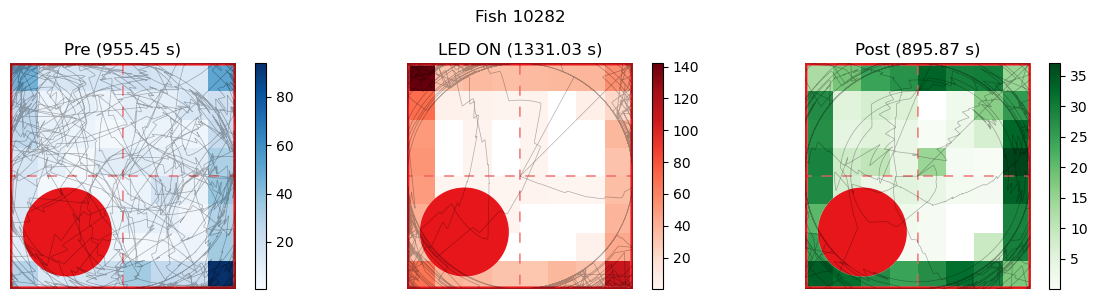

3it [00:51, 17.09s/it]


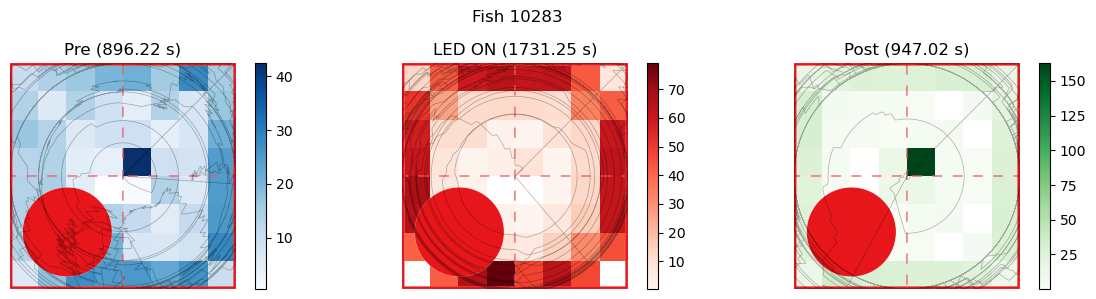

In [4]:
dirs = {
    10277: [
        r"E:\Open Field\Square OF\10277\S2-OF-Pre\res.16chFlt",
        r"E:\Open Field\Square OF\10277\S3-OF-LED\res.16chFlt",
        r"E:\Open Field\Square OF\10277\S4-OF-Post\res.16chFlt"
    ],
    10278: [
        r"E:\Open Field\Square OF\10278\S2-OF-Pre\res.16chFlt",
        r"E:\Open Field\Square OF\10278\S3-OF-LED\res.16chFlt",
        r"E:\Open Field\Square OF\10278\S4-OF-Post\res.16chFlt"
    ],
    10280: [
        r"E:\Open Field\Square OF\10280\S2-OF-Pre\res.16chFlt",
        r"E:\Open Field\Square OF\10280\S3-OF-LED\res.16chFlt",
        r"E:\Open Field\Square OF\10280\S4-OF-Post\res.16chFlt"
    ],
    10281: [
        r"E:\Open Field\Square OF\10281\S2-OF-Pre\res.16chFlt",
        r"E:\Open Field\Square OF\10281\S3-OF-LED\res.16chFlt",
        r"E:\Open Field\Square OF\10281\S4-OF-Post\res.16chFlt"
    ],
    10282: [
        r"E:\Open Field\Square OF\10282\S2-OF-Pre\res.16chFlt",
        r"E:\Open Field\Square OF\10282\S3-OF-LED\res.16chFlt",
        r"E:\Open Field\Square OF\10282\S4-OF-Post\res.16chFlt"
    ],
    10283: [
        r"E:\Open Field\Square OF\10283\S2-OF-Pre\res.16chFlt",
        r"E:\Open Field\Square OF\10283\S3-OF-LED\res.16chFlt",
        r"E:\Open Field\Square OF\10283\S4-OF-Post\res.16chFlt"
    ]
}

for fs in [10277, 10278, 10280, 10281, 10282, 10283]:
    # Visualize occupancy for each session
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 3))
    cmaps = ["Blues", "Reds", "Greens"]
    titles = ["Pre Session", "LED Session", "Post Session"]
    img = plt.imread(r"D:\Yao Shuyang\En Lab\Utils\Landmarks - 2.png")

    for session_idx, session_dir in tqdm(enumerate(dirs[fs])):
        title = ["Pre", "LED ON", "Post"][session_idx]
        ax = Clear_Axes(axes[session_idx])
        
        res_ax = import16chFlt(session_dir, nchannel=28)
        idx = np.where(
            (res_ax['behav_time'] > 5)
        )[0]
        for k in res_ax.keys():
            res_ax[k] = res_ax[k][idx]
            
        res_ax['behav_pos_x'] = np.clip(res_ax['behav_pos_x'], 35+1e-3, 65-1e-3)
        res_ax['behav_pos_y'] = np.clip(res_ax['behav_pos_y'], 35+1e-3, 65-1e-3)
            
        occu2d = get_occupancy2D(
            res_ax['behav_pos_y'], 
            res_ax['behav_pos_x'],
            x_bins=8, 
            y_bins=8,
            x_range=(35, 65), 
            y_range=(35, 65)
        )
        occu2d[occu2d < 1e-3] = np.nan
        
        im = ax.imshow(occu2d/6000, cmap=cmaps[session_idx], extent=[35, 65, 65, 35])
        ax.imshow(img, extent=[35, 65, 35, 65])
        cbar = plt.colorbar(im, ax=ax)
        ax.plot(res_ax['behav_pos_x'], res_ax['behav_pos_y'], color='k', alpha=0.3, lw=0.5)
        ax.set_title(f"{title} ({res_ax['behav_time'][-1]-5:.2f} s)")
    plt.suptitle(f"Fish {fs}")
    plt.tight_layout()
    plt.show()

C:\Users\Shuyang Yao\AppData\Local\Temp\ipykernel_27116\2024338823.py:68: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.stripplot(


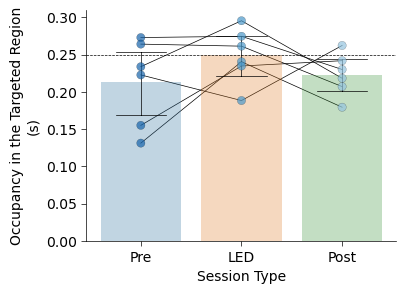

F_onewayResult(statistic=1.6274884399661989, pvalue=0.23088690944235687)
TtestResult(statistic=-1.5742128934744164, pvalue=0.1762526595512258, df=5)


In [7]:
if exists(join(figdata, f"{code_id} [Occupancy].pkl")) == False:
    OccuData = {
        "Fish": [],
        "Quarter": [],
        "Occupancy": [],
        "Session Type": []
    }
    
    for fs in dirs.keys():
        print(fs, " ------------------")
        for session_idx, session_dir in tqdm(enumerate(dirs[fs])):
            res_ax = import16chFlt(session_dir, nchannel=28)
            idx = np.where(
                (res_ax['behav_time'] > 5)
            )[0]
            
            for k in res_ax.keys():
                res_ax[k] = res_ax[k][idx]
                
            res_ax['behav_pos_x'] = np.clip(res_ax['behav_pos_x'], 35+1e-3, 65-1e-3)
            res_ax['behav_pos_y'] = np.clip(res_ax['behav_pos_y'], 35+1e-3, 65-1e-3)
            
            occu2d = get_occupancy2D(
                res_ax['behav_pos_y'], 
                res_ax['behav_pos_x'],
                x_bins=2, 
                y_bins=2,
                x_range=(35, 65), 
                y_range=(35, 65)
            )
            occu2d[occu2d < 1e-3] = 0
            
            for quarter_idx in range(4):
                OccuData["Fish"].append(fs)
                OccuData["Quarter"].append(quarter_idx + 1)
                OccuData["Occupancy"].append(occu2d.flat[quarter_idx] / occu2d.sum())
                OccuData["Session Type"].append(["Pre", "LED", "Post"][session_idx])
        print()
                
    for key in OccuData.keys():
        OccuData[key] = np.array(OccuData[key])
        
    with open(join(figdata, f"{code_id} [Occupancy].pkl"), "wb") as f:
        pickle.dump(OccuData, f)
        
    OccuD = pd.DataFrame(OccuData)
    OccuD.to_excel(join(figdata, f"{code_id} [Occupancy].xlsx"), index=False)
    print(len(OccuD))
else:
    with open(join(figdata, f"{code_id} [Occupancy].pkl"), "rb") as f:
        OccuData = pickle.load(f)
        
fig = plt.figure(figsize=(4, 3))
ax = Clear_Axes(plt.axes(), close_spines = ['top', 'right'], ifxticks=True, ifyticks=True)
subdata = SubDict(OccuData, np.where(OccuData["Quarter"] == 1)[0])
sns.barplot(
    x="Session Type",
    y="Occupancy",
    hue="Session Type",
    data=subdata,
    ax=ax,
    zorder=1,
    capsize=0.5,
    err_kws={'linewidth': 0.5, 'color':'k'},
    legend=False,
    alpha=0.3
)
sns.stripplot(
    x="Session Type",
    y="Occupancy",
    hue="Session Type",
    jitter=0.0,
    size=6,
    palette=sns.color_palette("Blues", 4)[::-1],
    linewidth=0.15,
    edgecolor='k',
    data=subdata,
    ax=ax,
    zorder=2,
    alpha=0.7,
    legend=False
)
for fish in np.unique(subdata["Fish"]):
    idx_pre = np.where((subdata["Fish"] == fish) & (subdata["Session Type"] == "Pre"))[0]
    idx_led = np.where((subdata["Fish"] == fish) & (subdata["Session Type"] == "LED"))[0]
    idx_post = np.where((subdata["Fish"] == fish) & (subdata["Session Type"] == "Post"))[0]
    for pre, led, post in zip(idx_pre, idx_led, idx_post):
        ax.plot(
            [0, 1, 2],
            [subdata["Occupancy"][pre], subdata["Occupancy"][led], subdata["Occupancy"][post]],
            color='k',
            linewidth=0.5,
            zorder=0
        )
ax.axhline(0.25, color='k', linestyle='--', linewidth=0.5)
ax.set_ylabel("Occupancy in the Targeted Region\n(s)")

plt.show()

idx_pre = np.where(subdata["Session Type"] == "Pre")[0]
idx_led = np.where(subdata["Session Type"] == "LED")[0]
idx_post = np.where(subdata["Session Type"] == "Post")[0]
print(f_oneway(
    subdata["Occupancy"][idx_pre],
    subdata["Occupancy"][idx_led]
))
print(ttest_rel(
    subdata["Occupancy"][idx_pre],
    subdata["Occupancy"][idx_led]
))

In [18]:
pos = np.array([37])

occ = get_occupancy2D(
    pos,
    pos, 
    x_bins=2, 
    y_bins=2,
    x_range=(35, 65), 
    y_range=(35, 65)
)
print(occ)

[[1. 0.]
 [0. 0.]]
